In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("All libraries imported successfully!")

KeyError: '__reduce_cython__'

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All libraries imported successfully!")

TensorFlow: 2.21.0
NumPy: 2.1.3
Scikit-learn: 1.9.1
All libraries imported successfully!


In [2]:
# Cell 2: Load the MNIST dataset

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


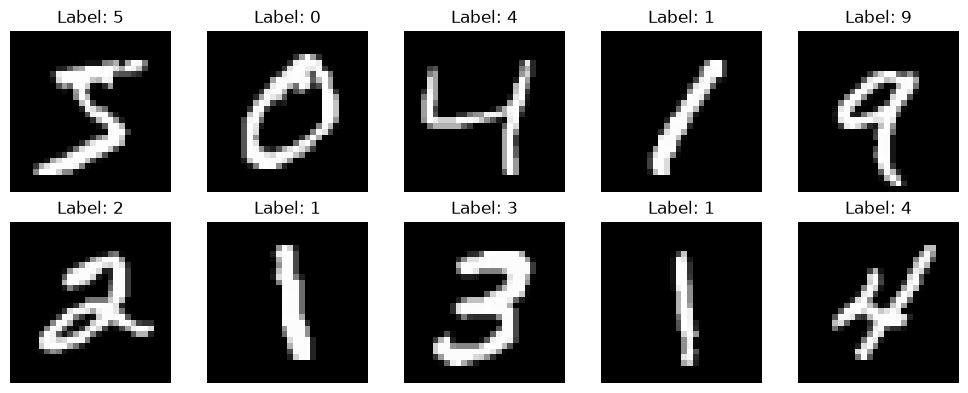

In [3]:
# Cell 3: Visualize handwritten digits

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# Cell 4: Preprocess the images

# Convert pixel values from 0–255 to 0–1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension for CNN
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [5]:
# Cell 5: Build the CNN model

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # Extract image features
    tf.keras.layers.Conv2D(
        32, kernel_size=(3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Conv2D(
        64, kernel_size=(3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Convert features into classification output
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Cell 6: Configure the model for training

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [7]:
# Cell 7: Train the CNN model

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9186 - loss: 0.2615 - val_accuracy: 0.9820 - val_loss: 0.0622
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9721 - loss: 0.0929 - val_accuracy: 0.9842 - val_loss: 0.0520
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9799 - loss: 0.0683 - val_accuracy: 0.9890 - val_loss: 0.0410
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9832 - loss: 0.0545 - val_accuracy: 0.9870 - val_loss: 0.0500
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9857 - loss: 0.0457 - val_accuracy: 0.9900 - val_loss: 0.0363


In [8]:
# Cell 8: Evaluate the trained model

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0312
Test Accuracy: 98.89%


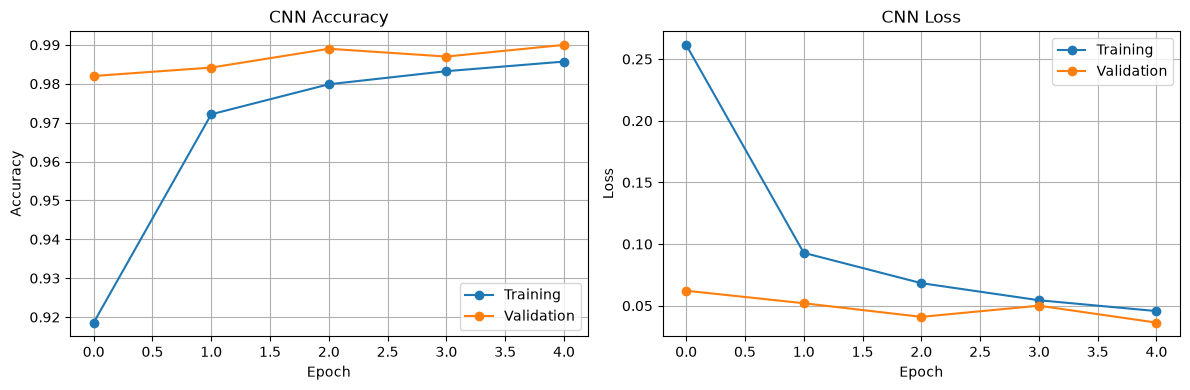

In [9]:
# Cell 9: Visualize training performance

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], marker="o", label="Training")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], marker="o", label="Training")
plt.plot(history.history["val_loss"], marker="o", label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
# Cell 10: Predict digits from test images

predictions = model.predict(x_test[:10], verbose=0)

predicted_labels = np.argmax(predictions, axis=1)

for i in range(10):
    confidence = np.max(predictions[i]) * 100

    print(
        f"Image {i}: Actual = {y_test[i]}, "
        f"Predicted = {predicted_labels[i]}, "
        f"Confidence = {confidence:.2f}%"
    )

Image 0: Actual = 7, Predicted = 7, Confidence = 100.00%
Image 1: Actual = 2, Predicted = 2, Confidence = 100.00%
Image 2: Actual = 1, Predicted = 1, Confidence = 100.00%
Image 3: Actual = 0, Predicted = 0, Confidence = 100.00%
Image 4: Actual = 4, Predicted = 4, Confidence = 99.99%
Image 5: Actual = 1, Predicted = 1, Confidence = 100.00%
Image 6: Actual = 4, Predicted = 4, Confidence = 99.76%
Image 7: Actual = 9, Predicted = 9, Confidence = 99.98%
Image 8: Actual = 5, Predicted = 5, Confidence = 92.54%
Image 9: Actual = 9, Predicted = 9, Confidence = 99.97%


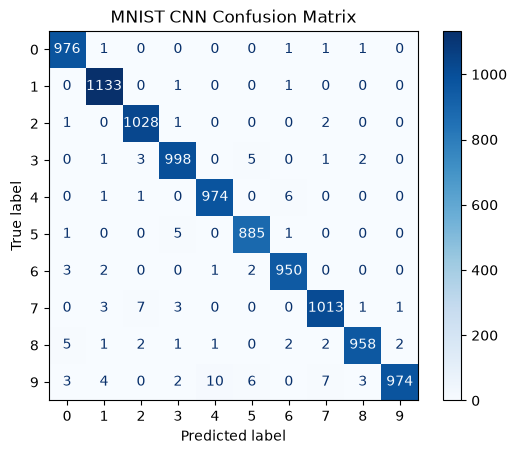

In [11]:
# Cell 11: Evaluate classification errors

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

all_predictions = model.predict(x_test, verbose=0)
predicted_labels = np.argmax(all_predictions, axis=1)

cm = confusion_matrix(y_test, predicted_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("MNIST CNN Confusion Matrix")
plt.show()

In [12]:
# Cell 12: Save the trained model

import os

os.makedirs("models", exist_ok=True)

model.save("models/mnist_cnn.keras")

print("Model saved successfully!")

Model saved successfully!
